# Extended Data Fig. 5: task, novelty, SWR rate and avalanches (panels)

Reads its tables from `../csv/FigS5_AG_task_novelty_avalanches/` and saves its panels to `../figure_output/supplementary/FigS5/`. The drawing code of d (the Extended Data "FigS1_C_SNR_S2C_d2 uncertainty" notebook) and g (`fig2_new.panel_dcc`) is included here and reads the exported table. d2 = d2 (2024 Euclidean, AR p = 20, 40 ms). Stars: *p < 0.05, **p < 0.01, ***p < 0.001, ****p < 0.0001.

- **a** T-maze alternation, fraction correct per session (17 sessions, 6 mice); one-sided signed-rank vs 0.5.
- **b** Novelty: Δ (post − mid sleep) of d2 normalised by baseline, control vs novel sessions, non-overlapping windows; star = mixed model S2 × novel; the ED2a schematic above it.
- **c** SWR rate presleep vs postsleep, 9 sessions, non-overlapping; star = mixed model on the session means.
- **d** d2 (z) and its uncertainty by SWR-rate sextile (non-overlapping); star = linear trend of the six means.
- **e** Avalanche example, PPP20_day4 NREM, 1× IEI, 30th percentile, low vs high local SWR rate.
- **f** DCC and KS distance, low vs high SWR rate, 16 sessions; paired signed-rank.
- **g** DCC by SWR-rate tercile, 16 sessions; high vs low paired signed-rank.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sys.path.insert(0, os.path.abspath('.'))           # figure_scripts
import final_figs as F                             # styles, save, stars, crops

CSV = os.path.join(F.REPO, "csv", "FigS5_AG_task_novelty_avalanches")
read = lambda name, **k: pd.read_csv(os.path.join(CSV, name), float_precision="round_trip", **k)   # noqa: E731
ST = read("stats.csv").set_index(["panel", "quantity"]).value       # every number printed on a panel
RC = json.load(open(os.path.join(CSV, "rcparams.json"), encoding="utf-8"))


def rc(fig_id, when):
    """matplotlib's settings when this panel was created ("draw") or saved ("save")"""
    mpl.rcdefaults()
    mpl.rcParams.update(RC[fig_id][when])

## a: T-maze performance

a: fraction correct vs chance (0.5), one-sided Wilcoxon signed-rank p = 0.00015; n = 17 sessions from 6 mice


saved figure_output\supplementary\FigS5\FigS5_A_tmaze_performance.svg / .png


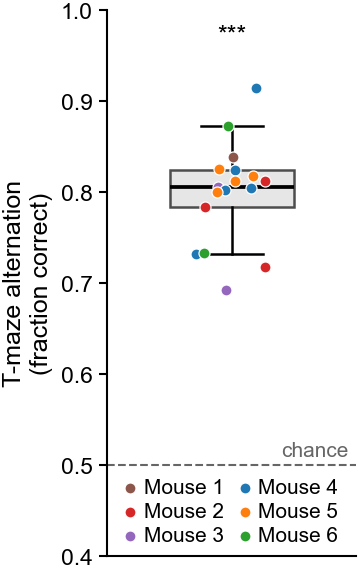

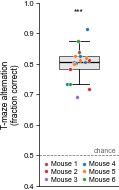

In [2]:
# a: T-maze alternation performance, one dot per session coloured by mouse (Mouse 1-6, the colours of Fig. 1d).
# Lab: m25_tmaze_box.py -> m25_tmaze_sessions.csv (all T-maze trials of the day per session). Statistic as the
# producer's: one-sided signed-rank of the session fractions against chance (0.5).
S = read("a_tmaze_sessions.csv")                  # lab: S = pd.read_csv(M25.OUT_CSV)
LABEL, COLOR = dict(zip(S.animal, S.mouse_label)), dict(zip(S.animal, S.mouse_color))   # lab: M25.MOUSE_LABEL / MOUSE_COL
w = stats.wilcoxon(S.frac_correct - 0.5, alternative="greater")
print(f"a: fraction correct vs chance (0.5), one-sided Wilcoxon signed-rank p = {w.pvalue:.2g}; n = {len(S)} sessions "
      f"from {S.animal.nunique()} mice")
rc("FigS5_A_tmaze_performance", "draw")            # lab: F.final_style()
fig, ax = plt.subplots(figsize=(32 * F.MM, 50 * F.MM), layout="constrained")
ax.boxplot(S.frac_correct, positions=[0], widths=0.5, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="0.9", edgecolor="0.3", lw=0.6), medianprops=dict(color="k", lw=0.9),
           whiskerprops=dict(lw=0.6), capprops=dict(lw=0.6))
rng = np.random.default_rng(1)                     # the producer's jitter
for a in sorted(S.animal.unique(), key=lambda x: LABEL[x]):
    g = S[S.animal == a]
    ax.scatter(rng.uniform(-0.15, 0.15, len(g)), g.frac_correct, s=7, color=COLOR.get(a, "0.5"),
               edgecolor="white", lw=0.3, zorder=3, label=LABEL[a])
ax.axhline(0.5, color="0.4", ls="--", lw=0.5)
ax.text(0.47, 0.505, "chance", fontsize=5, color="0.4", va="bottom", ha="right")
ax.text(0, 0.985, F.stars(w.pvalue), ha="center", va="top")
ax.set_xlim(-0.5, 0.5); ax.set_ylim(0.4, 1.0); ax.set_xticks([])
ax.set_ylabel("T-maze alternation\n(fraction correct)")
ax.legend(frameon=False, fontsize=5, loc="lower left", ncol=2, handletextpad=0.05, columnspacing=0.4,
          borderaxespad=0.1, labelspacing=0.25)
rc("FigS5_A_tmaze_performance", "save")
F.show(F.save(fig, "FigS5_A_tmaze_performance"))

## b: novelty

cropped Extended Data Fig2.svg [4.2, 5.6, 36.0 x 11.5] -> figure_output\supplementary\FigS5\FigS5_B_schematic_novel_familiar.svg (36.0 x 11.5 mm)


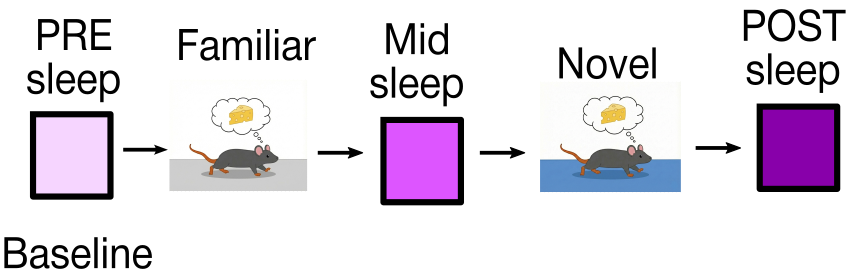

b: novel vs familiar, linear mixed model p = 0.017, two-sided permutation p = 0.078; n = 17 sessions (9 novel, 8 familiar)


saved figure_output\supplementary\FigS5\FigS5_B_novel_vs_control.svg / .png


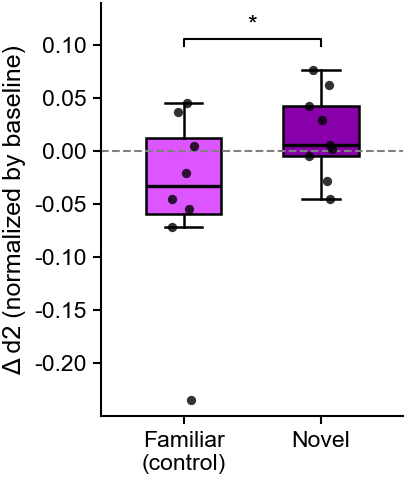

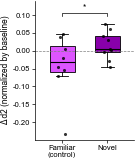

In [3]:
# b: novelty, one panel -- control vs novel, each box the per-session change from mid- to post-task sleep of d2
# normalised by baseline. d2 = d2 (2024 Euclidean, p = 20, 40 ms); d2_rel = (d2 - m_pre) / (d2 + m_pre), m_pre = the
# session's pre-task sleep; per session the median d2_rel per phase; Delta = post - mid. Non-overlapping windows.
# Lab: ed2a_novel_vs_control.per_session on ed_nonoverlap_tables/d2_rel_novel_familiar.csv; the star is its mixed
# model (lmm_interaction), the permutation p is printed.

# ---- the schematic (Extended Data Fig. 2a; mm units), cropped, its letter left out
ED2 = os.path.join(CSV, "assets", "Extended Data Fig2.svg")
F.crop_svg(ED2, "FigS5_B_schematic_novel_familiar", 4.2, 5.6, 36.0, 11.5, drop_ids=["text910277-5-8"], unit_mm=1.0)
_sch = F.stem("FigS5_B_schematic_novel_familiar") + ".svg"          # label spelling corrected in the copy
_t = open(_sch, encoding="utf-8").read(); assert _t.count(">Familar<") == 1
open(_sch, "w", encoding="utf-8").write(_t.replace(">Familar<", ">Familiar<"))
import subprocess; subprocess.run([F.INKSCAPE, _sch, "--export-type=png", "--export-dpi=600", "--export-background=#ffffff",
                                  f"--export-filename={_sch[:-4]}.png"], capture_output=True)
F.show(F.stem("FigS5_B_schematic_novel_familiar") + ".png")

s = read("b_sessions.csv")                         # lab: per_session(...d2_rel_novel_familiar.csv..., "median")
p_perm, p_lmm = ST["b", "p_permutation"], ST["b", "p"]
print(f"b: novel vs familiar, linear mixed model p = {p_lmm:.2g}, two-sided permutation p = {p_perm:.2g}; n = {len(s)} "
      f"sessions ({int((s.novel == 1).sum())} novel, {int((s.novel == 0).sum())} familiar)")

COL = {"control": "#dd55ff", "novel": "#8800aa"}   # panel colours
rc("FigS5_B_novel_vs_control", "draw")             # lab: F.final_style()
fig, ax = plt.subplots(figsize=(36 * F.MM, 42 * F.MM), layout="constrained")
groups = [("control", s[s.novel == 0].delta.to_numpy()), ("novel", s[s.novel == 1].delta.to_numpy())]
bp = ax.boxplot([g for _, g in groups], positions=[0, 1], widths=0.55, patch_artist=True, showfliers=False,
                medianprops=dict(color="k", lw=0.8), boxprops=dict(lw=0.6), whiskerprops=dict(lw=0.6), capprops=dict(lw=0.6))
for patch, (name, _) in zip(bp["boxes"], groups):
    patch.set_facecolor(COL[name])
rng = np.random.default_rng(0)
for i, (_, g) in enumerate(groups):
    ax.scatter(i + rng.uniform(-0.09, 0.09, g.size), g, s=5, color="k", alpha=0.8, lw=0, zorder=3)
ax.axhline(0, ls="--", lw=0.5, color="gray")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Familiar\n(control)", "Novel"]); ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("Δ d2 (normalized by baseline)")   # Δ = post − mid sleep: in the legend
lo, hi = ax.get_ylim(); span = hi - lo
F.bracket(ax, 0, 1, hi + 0.04 * span, F.stars(p_lmm), h=0.02 * span)
ax.set_ylim(lo, hi + 0.14 * span)
rc("FigS5_B_novel_vs_control", "save")
F.settle(fig)
F.drop_counts(fig)
F.show(F.save(fig, "FigS5_B_novel_vs_control"))

## c: SWR rate presleep vs postsleep

c: SWR rate post vs pre, paired linear mixed model p = 2.03e-09; n = 9 sessions


saved figure_output\supplementary\FigS5\FigS5_C_swr_rate_prepost.svg / .png


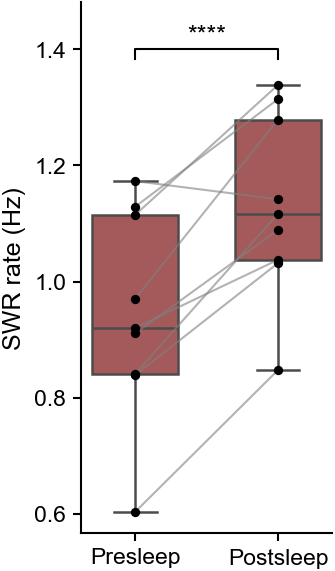

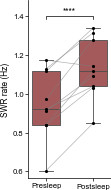

In [4]:
# c: SWR rate, presleep vs postsleep (the mid-session sleep), NREM, per-session means on non-overlapping windows, 9
# sessions. Lab: the Fig. 2a notebook's per-session table (fig2a_prepost_sessions_disjoint.csv); the star is that
# notebook's mixed model on the session means, (1|animal) + (1|animal_day), read from its run's log.
P = read("c_swr_rate_sessions.csv", index_col="animal_day")
p_c = ST["c", "p"]
print(f"c: SWR rate post vs pre, paired linear mixed model p = {p_c:.3g}; n = {len(P)} sessions")
rc("FigS5_C_swr_rate_prepost", "draw")             # lab: F.final_style()
fig, ax = plt.subplots(figsize=(30 * F.MM, 50 * F.MM), layout="constrained")
L = P.reset_index().melt(id_vars="animal_day", var_name="epoch2", value_name="rate")
order = ["Presleep", "Postsleep"]
sns.boxplot(data=L, x="epoch2", y="rate", order=order, color="#b04d4e", showfliers=False, width=0.6, linewidth=0.6,
            ax=ax, zorder=2)
for _, r in P.iterrows():
    ax.plot([0, 1], [r.Presleep, r.Postsleep], color="gray", alpha=0.6, lw=0.5, zorder=3)
ax.scatter(np.r_[np.zeros(len(P)), np.ones(len(P))], np.r_[P.Presleep, P.Postsleep], s=5, color="k", zorder=4, lw=0)
lo, hi = ax.get_ylim(); span = hi - lo
F.bracket(ax, 0, 1, hi + 0.03 * span, F.stars(p_c), h=0.02 * span)
ax.set_ylim(lo, hi + 0.13 * span)
ax.set_xlabel(""); ax.set_ylabel("SWR rate (Hz)")
rc("FigS5_C_swr_rate_prepost", "save")
F.settle(fig)
F.drop_counts(fig)
F.show(F.save(fig, "FigS5_C_swr_rate_prepost"))

## d: d2 uncertainty by SWR rate

d: linear regression of the six sextile means, R² = 0.90, p = 0.004


saved figure_output\supplementary\FigS5\FigS5_D_d2_uncertainty_by_swr_rate.svg / .png


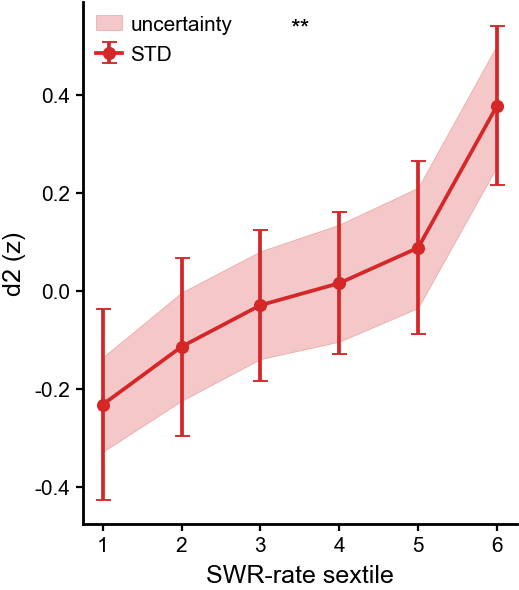

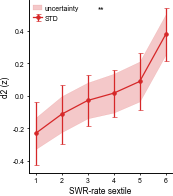

In [5]:
# d: d2 and its uncertainty by SWR-rate sextile -- the submitted Extended Data Fig. 2c on non-overlapping windows.
# Lab: the Previous_Rv1 notebook "FigS1_C_SNR_S2C_d2 uncertainty" run on the disjoint table
# (ed_nonoverlap_tables/d2_err_by_swr_rate_sextile.csv), its figure captured and restyled. Here: its per-sextile
# table (mean over files of the per-file mean d2 z, SD over files, mean propagated uncertainty) and its plotting
# step, pasted from plot_d2_by_rate_tile_pooled; the star is its linear trend of the six means.
Dd = read("d_sextiles.csv")
r2_d, p_d = ST["d", "R2"], ST["d", "p"]
print(f"d: linear regression of the six sextile means, R² = {r2_d:.2f}, p = {p_d:.2g}")
rc("FigS5_D_d2_uncertainty_by_swr_rate", "draw")
xs, means, errs, band = Dd.tile.to_numpy(int), Dd["mean"].to_numpy(), Dd["sd"].to_numpy(), Dd["uncertainty"].to_numpy()
color = "tab:red"
# ---- pasted: plot_d2_by_rate_tile_pooled, "4) plotting"
plt.figure(figsize=(5, 4))
ax = plt.gca()
ax.fill_between(xs, means - band, means + band, alpha=0.25, color=color, label="uncertainty")
plt.errorbar(xs, means, yerr=errs, fmt='-o', capsize=4, color=color, linewidth=2, label="STD")
plt.xticks(xs)
plt.ylabel("d² distance (z)")
plt.xlabel("Ripple rate quantiles (low → high)")
sns.despine()
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.legend(frameon=False, fontsize=12)
plt.tight_layout()
fig = plt.gcf()
# ---- the lab cell: labels, print size, star
ax.set_ylabel("d2 (z)"); ax.set_xlabel("SWR-rate sextile")
F.restyle(fig, 44, 50)
ax.text(0.5, 0.97, F.stars(p_d), transform=ax.transAxes, ha="center", va="top", fontsize=6)
rc("FigS5_D_d2_uncertainty_by_swr_rate", "save")
F.show(F.save(fig, "FigS5_D_d2_uncertainty_by_swr_rate"))

## e–g: avalanches

saved figure_output\supplementary\FigS5\FigS5_E_avalanche_example.svg / .png


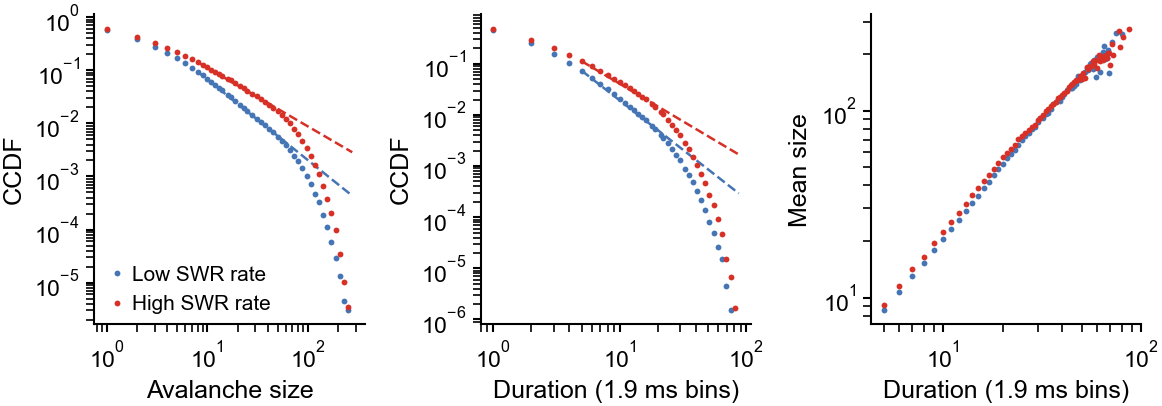

f DCC: high vs low SWR rate, two-sided Wilcoxon signed-rank p = 0.016; n = 16 sessions
f KS distance D: high vs low SWR rate, two-sided Wilcoxon signed-rank p = 0.0021; n = 16 sessions


saved figure_output\supplementary\FigS5\FigS5_F_dcc_ks_low_high.svg / .png


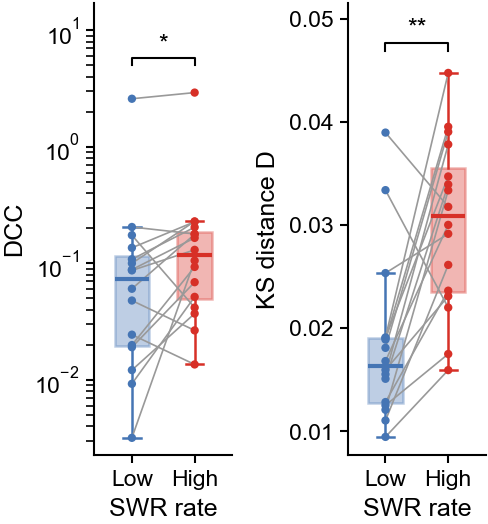

g: DCC higher in the high than the low tercile in 13 of 16 sessions, two-sided Wilcoxon signed-rank p = 0.011


saved figure_output\supplementary\FigS5\FigS5_G_dcc_by_swr_tercile.svg / .png


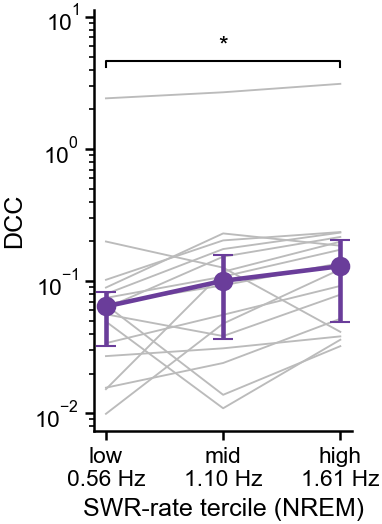

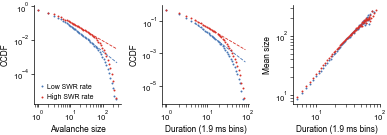

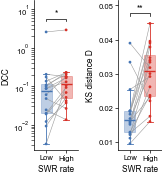

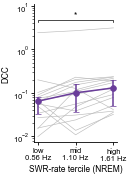

In [6]:
# e-g: neuronal avalanches, from the avalanche pipeline (ripple_criticality_batch.ipynb; bin = 1x the population's mean
# inter-event interval, detection strictly inside NREM, 30th-percentile activity threshold, common xmin; each
# avalanche labelled by the local SWR rate, 10 s window, median split low / high, terciles for g). No exponents on the
# panels. Low / high colours as m22_dcc_threshold_box.C.
C = {"LOW": "#4575b4", "HIGH": "#d73027"}

# ---- e: the example session PPP20_day4 (the batch notebook's run_session; lab: the cached
# figs3e_example_PPP20_day4_avalanches.npz). Here the plotted points: CCDF of sizes and durations on the log grid,
# the power-law line from the common xmin (the pipeline's fit_powerlaw), mean size per duration.
Ep = read("e_points.csv")
iei_ms = ST["e", "bin_ms"]
pts = lambda panel, key, kind: Ep[(Ep.panel == panel) & (Ep.group == key) & (Ep.kind == kind)]   # noqa: E731
rc("FigS5_E_avalanche_example", "draw")            # lab: F.final_style()
fig, axes = plt.subplots(1, 3, figsize=(100 * F.MM, 36 * F.MM), layout="constrained")
for ax, panel, lab in ((axes[0], "size", "Avalanche size"), (axes[1], "duration", f"Duration ({iei_ms:.1f} ms bins)")):
    for key, name in (("LOW", "Low SWR rate"), ("HIGH", "High SWR rate")):
        q = pts(panel, key, "ccdf"); ax.loglog(q.x.to_numpy(), q.y.to_numpy(), "o", ms=1.4, mew=0, color=C[key], label=name)
        q = pts(panel, key, "fit"); ax.loglog(q.x.to_numpy(), q.y.to_numpy(), "--", color=C[key], lw=0.6)
    ax.set_xlabel(lab); ax.set_ylabel("CCDF")
axes[0].legend(frameon=False, loc="lower left", fontsize=5, handletextpad=0.1, borderaxespad=0.1)
ax = axes[2]
for key in ("LOW", "HIGH"):
    q = pts("meansize", key, "meansize"); ax.loglog(q.x.to_numpy(), q.y.to_numpy(), "o", ms=1.4, mew=0, color=C[key])
ax.set_xlabel(f"Duration ({iei_ms:.1f} ms bins)"); ax.set_ylabel("Mean size")
rc("FigS5_E_avalanche_example", "save")
F.show(F.save(fig, "FigS5_E_avalanche_example"))

# ---- f: DCC and KS distance, low vs high SWR rate, 30th percentile, per session (lab: m22's tables -- DCC from
# ripple_criticality_all_sessions.csv, common xmin; KS of the sizes from ks_xmin_convention.csv, bin_mult 1, xmin per
# group, ks_free); paired signed-rank over the 16 sessions
DCC = read("f_dcc_sessions.csv", index_col="session")
KS = read("f_ks_sessions.csv", index_col="session")
rc("FigS5_F_dcc_ks_low_high", "draw")
fig, axes = plt.subplots(1, 2, figsize=(43 * F.MM, 46 * F.MM), layout="constrained")
for ax, P, ylab, log in ((axes[0], DCC, "DCC", True), (axes[1], KS, "KS distance D", False)):
    for j, grp in enumerate(("LOW", "HIGH")):
        ax.boxplot(P[grp], positions=[j], widths=0.55, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=C[grp], alpha=0.35, edgecolor=C[grp], lw=0.6),
                   medianprops=dict(color=C[grp], lw=1.0), whiskerprops=dict(color=C[grp], lw=0.6),
                   capprops=dict(color=C[grp], lw=0.6))
    for _, r in P.iterrows():
        ax.plot([0, 1], [r.LOW, r.HIGH], "-", color="#999999", lw=0.4, zorder=2)
    ax.scatter(np.r_[np.zeros(len(P)), np.ones(len(P))], np.r_[P.LOW, P.HIGH], s=4, lw=0, zorder=3,
               color=[C["LOW"]] * len(P) + [C["HIGH"]] * len(P))
    if log:
        ax.set_yscale("log")
    pw = stats.wilcoxon(P.HIGH, P.LOW).pvalue
    print(f"f {ylab.splitlines()[0]}: high vs low SWR rate, two-sided Wilcoxon signed-rank p = {pw:.2g}; "
          f"n = {len(P)} sessions")
    lo_, hi_ = ax.get_ylim()
    if log:
        y = hi_ * 1.4
        ax.plot([0, 0, 1, 1], [y / 1.15, y, y, y / 1.15], color="k", lw=0.5)
        ax.text(0.5, y * 1.05, F.stars(pw), ha="center", va="bottom"); ax.set_ylim(lo_, y * 3)
    else:
        span = hi_ - lo_
        F.bracket(ax, 0, 1, hi_ + 0.03 * span, F.stars(pw), h=0.02 * span); ax.set_ylim(lo_, hi_ + 0.13 * span)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Low", "High"]); ax.set_xlim(-0.6, 1.6)
    ax.set_xlabel("SWR rate"); ax.set_ylabel(ylab)
    if not log:                                    # KS: a tick every 0.01, labelled 0.01, 0.02 ...
        from matplotlib.ticker import MultipleLocator, FormatStrFormatter
        ax.yaxis.set_major_locator(MultipleLocator(0.01)); ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
rc("FigS5_F_dcc_ks_low_high", "save")
F.show(F.save(fig, "FigS5_F_dcc_ks_low_high"))

# ---- g: DCC by SWR-rate tercile, per session (median and IQR over sessions, grey = sessions; high vs low
# signed-rank). Lab: fig2_new.panel_dcc on the same table (30th percentile, groups T1-T3), restyled; its drawing
# pasted below, reading the per-session tercile table
Gt = read("g_dcc_terciles.csv", index_col="session")
P = Gt[["T1", "T2", "T3"]]
R = Gt[["swr_rate_T1", "swr_rate_T2", "swr_rate_T3"]].rename(columns=lambda c: c.replace("swr_rate_", ""))
rc("FigS5_G_dcc_by_swr_tercile", "draw")           # lab: F.native_style()
fig, ax = plt.subplots(figsize=(34 * F.MM, 46 * F.MM), layout="constrained")
# ---- pasted: fig2_new.panel_dcc (C_DCC = #6a3d9a; _despine)
x = np.array([1, 2, 3])
for _, row in P.iterrows():
    ax.plot(x, row.to_numpy(), "-", color="#bbbbbb", lw=0.9, zorder=1)
med, q1, q3 = P.median().to_numpy(), P.quantile(.25).to_numpy(), P.quantile(.75).to_numpy()
ax.errorbar(x, med, yerr=[med - q1, q3 - med], fmt="o-", color="#6a3d9a", lw=2.2, ms=7, capsize=4, zorder=3)
ax.set_yscale("log")
t31, p31 = int((P.T3 > P.T1).sum()), stats.wilcoxon(P.T3, P.T1).pvalue
ax.text(0.5, 1.0, f"high > low {t31}/{len(P)} {F.stars(p31)}", transform=ax.transAxes, ha="center", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([f"low\n{R.T1.median():.2f} Hz", f"mid\n{R.T2.median():.2f} Hz", f"high\n{R.T3.median():.2f} Hz"])
ax.set_xlabel("SWR-rate tercile (NREM)")
ax.set_ylabel("avalanche DCC\n(1× IEI; median, IQR)")
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
print(f"g: DCC higher in the high than the low tercile in {t31} of {len(P)} sessions, two-sided Wilcoxon signed-rank "
      f"p = {p31:.2g}")
# ---- the lab cell: labels, print size, the "high > low" text as a bracket
ax.set_xlabel("SWR-rate tercile (NREM)"); ax.set_ylabel("DCC")
F.shrink(fig)
t = [t for t in ax.texts if t.get_text().startswith("high > low")][0]
lab = t.get_text().replace("high > low", "").strip(); t.remove()
y = max(l.get_ydata().max() for l in ax.lines if len(l.get_ydata())) * 1.5
ax.plot([1, 1, 3, 3], [y / 1.12, y, y, y / 1.12], color="k", lw=0.5, clip_on=False)
ax.text(2, y * 1.05, lab, ha="center", va="bottom", fontsize=6)
ax.set_ylim(ax.get_ylim()[0], y * 2.4)
rc("FigS5_G_dcc_by_swr_tercile", "save")
F.settle(fig)
F.drop_counts(fig)
F.show(F.save(fig, "FigS5_G_dcc_by_swr_tercile"))